**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_013_공식형_회귀_반도체공정불량예측

### **맑은팹의 <span style="color:darkgreen">임계치수 오차(nm)</span> 예측 프로젝트**
---

- 도메인 : 반도체 공정 불량 예측
- 목  표 : 임계치수 오차(nm)를 예측하는 인공지능모델 개발
- 최근 웨이퍼 로트 관련 현안이 늘면서 맑은팹은 데이터 기반의 판단 체계가 필요하다고 보고 있다.
- 맑은팹의 데이터팀은 축적된 웨이퍼 로트 데이터를 활용해 임계치수 오차(nm)를 예측하는 모델을 만들어 보기로 했다.
- 제공되는 데이터는 웨이퍼 로트 단위로 정리된 약 1,610건의 기록이다.
- 임계치수 오차(nm)를 미리 알 수 있다면 맑은팹의 운영 효율이 크게 개선될 것으로 보고 있다.

---

#### **[유의사항]**
- 답안 형태는 두 가지입니다. ① **결과 변수 저장형** — 가이드가 지정한 변수(예: `X_train`, `model`)에 결과를 저장하면 그 변수의 내용으로 채점합니다. ② **정답 입력형** — 코드 셀 **맨 아래** `정답NN`(빈칸이 여럿이면 `정답NN_1`, `정답NN_2`) 변수에 **값만** 입력합니다.
- 맨 위 **자동 채점 준비** 셀을 먼저 실행하면, 문항마다 `채점(번호)` 셀로 바로 ✅/❌ 를 확인하고 맨 끝 `채점()` 셀로 총점을 볼 수 있습니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 맑은팹의 데이터로 임계치수 오차(nm)를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, select_dtypes, min, max, idxmax, quantile, copy, clip, drop, reset_index, fillna, median, sort_values, mode, loc, value_counts, isin, get_dummies, info, Series, columns, shape) · NumPy(abs) · seaborn(violinplot) · matplotlib(import matplotlib.pyplot as plt, show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, MinMaxScaler, fit_transform, transform, LinearRegression, fit, RandomForestRegressor, coef_, predict, mean_squared_error) · TensorFlow(Keras)(Input, Model, EarlyStopping, compile, fit, Dense, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 2.98 / 5)
- 예상 소요 시간 : 약 129분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 반도체 공정 불량 예측 (제조)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- uid                   : 고유 식별번호
- base_date             : 기준 일자 (문자열 날짜)
- etch_rate             : 식각 속도(nm/min)
- chamber_temp          : 챔버 온도(℃)
- pressure_mtorr        : 공정 압력(mTorr)
- wafer_thk             : 웨이퍼 두께(㎛)
- rf_power              : RF 파워(W)
- particle_cnt          : 파티클 수
- cycle_time_min        : 공정 소요(분)
- vacuum_leak           : 진공 누설률
- chamber               : 챔버 (복수 값은 | 로 결합되어 있음)
- lot_type              : 로트 유형
- shift                 : 근무 조
- recipe                : 레시피
- cd_error              : 임계치수 오차(nm)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [2]:
import numpy as np
import seaborn as sns

### **1. 분석에 필요한 라이브러리 두 개를 아래 가이드의 별칭으로 한 번에 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) · matplotlib(import matplotlib.pyplot as plt) | 난이도: 기초 | 예상 시간: 3분</sub>

- `pandas` 의 별칭은 `pd`
- `matplotlib.pyplot` 의 별칭은 `plt`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 코드 셀 맨 아래에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [3]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
# (1) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답01 = 'plt'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

라이브러리마다 import 문을 따로 작성하고 각각 별칭을 붙입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 3글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pandas as pd
import matplotlib.pyplot as pl_

정답01 = 'pl_'   # 빈칸에 넣은 단어
```

</details>

### **2. 분석 데이터를 읽은 뒤 수치형 컬럼만 따로 모아 새 CSV 파일로 저장하고자 합니다. 제시된 가이드에 맞춰 처리하십시오.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, select_dtypes) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 읽어 올 파일 : data.csv → 데이터프레임 변수명 df_raw
    - df_raw 에서 **수치형 컬럼만** 선택해 변수 `num_df` 에 담으세요 (select_dtypes 활용)
    - `num_df` 를 `num_data.csv` 파일로 보관하세요 (행 번호(인덱스)는 저장하지 않도록 index=False)
- **[정답02]** 저장한 `num_df` 의 **컬럼 개수**는 몇 개로 나타나나요?
- 답안 : **[정답02]** 의 값만 코드 셀 맨 아래에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [5]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

df_raw = pd.read_csv('aa23-m3-data.csv')
num_df = df_raw.select_dtypes(include='number')
num_df.to_csv('./num_data.csv', index=False)

num_df.shape[1]


9

In [ ]:
# (2) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답02 = 9

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

수치형 컬럼만 고른 뒤 CSV 로 내보내는 메서드를 쓰세요. 저장한 num_df 의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `select_dtypes`, `to_csv`, `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_raw = pd.read_csv('./data.csv')
num_df = df_raw.select_dtypes(include='number')
num_df.to_csv('./num_data.csv', index=False)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
num_df.shape[__]
```

</details>

### **3. 공정 소요(분)(cycle_time_min)의 값이 어느 범위에 걸쳐 있는지, 가장 큰 값이 어느 행에 있는지 확인할 계획입니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(min, max, idxmax) | 난이도: 기초 | 예상 시간: 3분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- df_raw 의 cycle_time_min 컬럼에서 최솟값을 `col_min`, 최댓값을 `col_max`, **최댓값이 있는 행의 인덱스**를 `max_idx` 에 보관하세요
    - 최솟값은 `min()`, 최댓값은 `max()`, 최댓값의 인덱스는 `idxmax()` 를 사용하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 코드 셀 맨 아래에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [6]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

col_min = df_raw['cycle_time_min'].min()
col_max = df_raw['cycle_time_min'].max()
max_idx = df_raw['cycle_time_min'].idxmax()


In [ ]:
# (3) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답03 = 'idxmax'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

최솟값·최댓값을 구하는 메서드와, 최댓값의 위치(인덱스)를 구하는 메서드를 각각 쓰세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `min`, `max`, `idxmax`. 정답은 6글자이고 첫 글자는 `i` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
col_min = df_raw['cycle_time_min'].min()
col_max = df_raw['cycle_time_min'].max()
max_idx = df_raw['cycle_time_min'].idx___()

정답03 = 'idx___'   # 빈칸에 넣은 단어
```

</details>

### **4. 근무 조(shift) 별 챔버 온도(℃)(chamber_temp)의 분포 모양(밀도)을 비교하려 합니다. violinplot으로 시각화하십시오.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(violinplot) · matplotlib(show) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- seaborn 의 violinplot 으로 그래프를 그리세요
- X축: 근무 조(shift), Y축: 챔버 온도(℃)(chamber_temp)
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 코드 셀 맨 아래에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


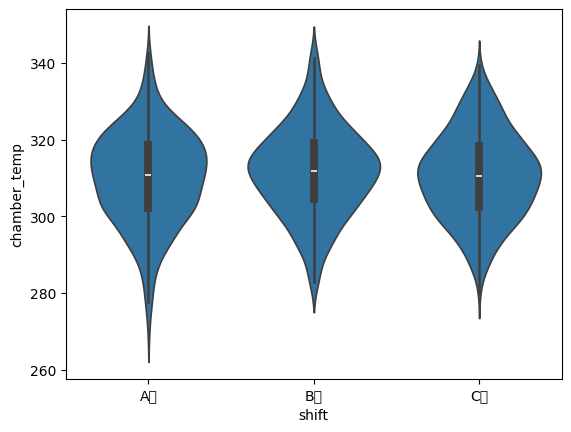

In [7]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.violinplot(data=df_raw, x='shift', y='chamber_temp')
plt.show()


In [ ]:
# (4) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답04 = 'violinplot'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

그룹별 분포의 밀도를 바이올린 모양으로 보여주는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.violinplot`. 정답은 10글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.violi_____(data=df_raw, x='shift', y='chamber_temp')
plt.show()

정답04 = 'violi_____'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 웨이퍼 두께(㎛)(wafer_thk) 컬럼의 극단값을 상·하위 5% 경계값으로 대체하고자 합니다.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, copy, clip, drop) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_raw
    - wafer_thk 의 5% 분위수를 low, 95% 분위수를 high 로 산출하세요 (변수명: low, high)
    - low 보다 작은 값은 low 로, high 보다 큰 값은 high 로 바꾸세요(행 삭제 없음)
    - 식별자 컬럼 uid 를 삭제한 사본에 적용해 df_clean 에 보관하세요
- **[결과 변수]** 결과는 반드시 `df_clean` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_clean.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [9]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

low, high = df_raw['wafer_thk'].quantile([0.05, 0.95])

df_clean = df_raw.drop(columns=['uid']).copy()
df_clean['wafer_thk'] = df_clean['wafer_thk'].clip(lower=low, upper=high)

print(df_clean.shape)

(1607, 14)


In [ ]:
# (5) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(1607, 14)

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수 두 개를 한 번에 구한 뒤 clip 에 하한/상한으로 넣습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `clip`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_clean` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
low, high = df_raw['wafer_thk'].quantile([0.05, 0.95])

df_clean = df_raw.drop(columns=['uid']).copy()
df_clean['wafer_thk'] = df_clean['wafer_thk'].clip(lower=low, upper=high)

# [df_clean] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_clean.shape)
```

</details>

### **6. 날짜 순서가 있는 데이터에서는 결측치를 이웃한 시점의 값으로 채우는 방법을 쓸 수 있습니다. 아래 가이드에 따라 처리하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(reset_index, fillna, median, sort_values) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_clean`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_clean (결과를 df_filled 에 저장)
    - base_date 컬럼(문자열 날짜, 사전순이 곧 시간순)으로 오름차순 정렬하고 인덱스를 0부터 다시 매기세요
    - 수치형 결측 컬럼(particle_cnt)은 바로 **뒤**(다음) 행의 값(bfill)으로 채우세요
    - 맨 앞(또는 맨 뒤)이라 여전히 남은 결측치는 해당 컬럼의 중앙값으로 채우세요
    - 범주형 결측 컬럼(shift)은 최빈값으로 채우세요
- **[결과 변수]** 결과는 반드시 `df_filled` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_filled.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [10]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

df_filled = df_clean.sort_values('base_date').reset_index(drop=True)
df_filled[['particle_cnt']] = df_filled[['particle_cnt']].bfill()
df_filled['particle_cnt'] = df_filled['particle_cnt'].fillna(df_filled['particle_cnt'].median())
df_filled['shift'] = df_filled['shift'].fillna(df_filled['shift'].mode()[0])

print(df_filled.shape)

(1607, 14)


In [ ]:
# (6) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
1607, 14

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

날짜순으로 정렬한 뒤, 이웃 값으로 채우는 메서드를 쓰고 남은 결측을 대표값으로 채웁니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `sort_values`, `bfill`, `fillna`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_filled` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
df_filled = df_clean.sort_values('base_date').reset_index(drop=True)
df_filled[['particle_cnt']] = df_filled[['particle_cnt']].bfill()
df_filled['particle_cnt'] = df_filled['particle_cnt'].fillna(df_filled['particle_cnt'].median())
df_filled['shift'] = df_filled['shift'].fillna(df_filled['shift'].mode()[0])

# [df_filled] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_filled.shape)
```

</details>

### **7. 원-핫 인코딩(One-Hot Encoding)은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 제시된 가이드에 맞춰 범주형 데이터를 처리하고 인코딩하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(loc, value_counts, isin, get_dummies) | 난이도: 어려움 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_filled`
- 다음 지침에 따라 데이터를 처리하는 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_filled
    - 챔버(chamber) 의 값 'C1|C2', 'C1|C3', 'C1|C4', 'C1|C5' 을(를) 'C1' 으로 치환하세요
    - 챔버(chamber) 의 값 'C2|C1', 'C2|C3', 'C2|C4', 'C2|C5' 을(를) 'C2' 으로 치환하세요
    - 챔버(chamber) 의 값 'C3|C1', 'C3|C2', 'C3|C4', 'C3|C5' 을(를) 'C3' 으로 치환하세요
    - 챔버(chamber) 의 값 'C4|C1', 'C4|C2', 'C4|C3', 'C4|C5' 을(를) 'C4' 으로 치환하세요
    - 챔버(chamber) 의 값 'C5|C1', 'C5|C2', 'C5|C3', 'C5|C4' 을(를) 'C5' 으로 치환하세요
    - 치환 후 범주별 개수를 출력하세요
- 남은 문자열 컬럼을 모두 원-핫 인코딩(get_dummies, drop_first=True)하는데 실행 중 예외가 발생합니다. 코드의 오류를 정정하고 결과를 df_final 에 저장하세요
- **[정답07]** 인코딩 후 df_final 의 **전체 컬럼 개수**는 몇 개인가요?
- 답안 : **[정답07]** 의 값만 코드 셀 맨 아래에 `정답07 = 값` 형태로 입력하세요
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [11]:
# (코드 셀) 아래 코드를 실행하세요 (채점하지 않음)

df_filled.loc[df_filled['chamber'].isin(['C1|C2', 'C1|C3', 'C1|C4', 'C1|C5']), 'chamber'] = 'C1'
df_filled.loc[df_filled['chamber'].isin(['C2|C1', 'C2|C3', 'C2|C4', 'C2|C5']), 'chamber'] = 'C2'
df_filled.loc[df_filled['chamber'].isin(['C3|C1', 'C3|C2', 'C3|C4', 'C3|C5']), 'chamber'] = 'C3'
df_filled.loc[df_filled['chamber'].isin(['C4|C1', 'C4|C2', 'C4|C3', 'C4|C5']), 'chamber'] = 'C4'
df_filled.loc[df_filled['chamber'].isin(['C5|C1', 'C5|C2', 'C5|C3', 'C5|C4']), 'chamber'] = 'C5'

print(df_filled['chamber'].value_counts())

chamber
C4    524
C2    393
C5    273
C3    215
C1    202
Name: count, dtype: int64


In [12]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_final = pd.get_dummies(data=df_filled, columns=['base_date', 'chamber', 'lot_type', 'shift', 'recipe'], drop_first=True)
df_final.info()

df_final.shape[1]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1607 entries, 0 to 1606
Columns: 859 entries, etch_rate to recipe_R-03
dtypes: bool(850), float64(9)
memory usage: 1.4 MB


859

In [ ]:
# (7) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답07 = 859

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

빈칸을 채워 치환 코드를 완성해 실행하세요. 값별 개수를 세는 Series 메서드입니다. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `isin`, `loc`, `value_counts`, `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_filled.loc[df_filled['chamber'].isin(['C1|C2', 'C1|C3', 'C1|C4', 'C1|C5']), 'chamber'] = 'C1'
df_filled.loc[df_filled['chamber'].isin(['C2|C1', 'C2|C3', 'C2|C4', 'C2|C5']), 'chamber'] = 'C2'
df_filled.loc[df_filled['chamber'].isin(['C3|C1', 'C3|C2', 'C3|C4', 'C3|C5']), 'chamber'] = 'C3'
df_filled.loc[df_filled['chamber'].isin(['C4|C1', 'C4|C2', 'C4|C3', 'C4|C5']), 'chamber'] = 'C4'
df_filled.loc[df_filled['chamber'].isin(['C5|C1', 'C5|C2', 'C5|C3', 'C5|C4']), 'chamber'] = 'C5'

print(df_filled['chamber'].value_counts())

df_final = pd.get_dummies(data=df_filled, columns=['base_date', 'chamber', 'lot_type', 'shift', 'recipe'], drop_first=True)
df_final.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_final.shape[__]
```

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 분리된 데이터의 크기를 확인하고자 합니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `df_final`
- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_final
    - 임계치수 오차(nm)(cd_error) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 할당하세요
    - 분리 결과는 X_train, X_valid, y_train, y_valid 순서로 받으세요
    - random_state 는 100 로 고정하세요
    - 분리에는 sklearn.model_selection 의 train_test_split 을 사용하세요
    - 데이터를 훈련 65 : 검증 35 로 분할합니다 (train_size=0.65)
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [13]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.model_selection import train_test_split

X = df_final.drop('cd_error', axis=1)
y = df_final['cd_error']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.65, random_state=100)

print(len(X_valid))

563


In [ ]:
# (8) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
563

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `X_valid` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.model_selection import train_test_split

X = df_final.drop('cd_error', axis=1)
y = df_final['cd_error']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.65, random_state=100)

# [X_valid] 결과 확인 (LMS 에는 이 출력값을 입력)
print(len(X_valid))
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (최솟값 0~최댓값 1 정규화)**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(MinMaxScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 다음 지침에 따라 스케일링 처리하는데 실행 중 예외가 발생합니다. 코드의 오류를 정정하세요
    - sklearn.preprocessing 에서 MinMaxScaler 를 import 하세요
    - MinMaxScaler 를 sc 변수에 설정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 보관하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 보관하세요
- **[정답09]** MinMaxScaler 적용 후 검증 데이터(X_valid)의 **최솟값**을 소수점 아래 둘째 자리까지 기입하세요
- 답안 : **[정답09]** 의 값만 코드 셀 맨 아래에 `정답09 = 값` 형태로 입력하세요
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [15]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import MinMaxScaler

sc = MinMaxScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

round(np.min(X_valid), 2)


np.float64(-0.05)

In [ ]:
# (9) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답09 = '-0.05'

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import MinMaxScaler

sc = MinMaxScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 임계치수 오차(nm)(cd_error)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. LinearRegression와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(LinearRegression, fit, RandomForestRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- LinearRegression 모델을 아래와 같이 만들어 `lin` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : 지정하지 않음(기본값)
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=100, max_depth=4
    - 난수 시드(random_state) : 42
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `lin`(LinearRegression) 의 절편(`intercept_`)을 소수 둘째 자리까지 작성하세요
- 답안 : **[정답10]** 의 값만 코드 셀 맨 아래에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [16]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
rf.fit(X_train, y_train)

round(lin.intercept_, 2)


np.float64(0.31)

In [ ]:
# (10) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답10 = '0.31'

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 선형 모델은 학습 후 intercept_ 속성에 절편을 저장합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `LinearRegression`, `fit`, `RandomForestRegressor`, `intercept_`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
rf.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(lin.intercept_, __)
```

</details>

### **11. 선형회귀 모델의 계수 크기로 어떤 변수가 예측에 큰 영향을 주는지 해석하려 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(sort_values, Series, columns) · NumPy(abs) · scikit-learn(coef_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `lin`
- 학습된 lin 의 계수(`coef_`)의 **절댓값**을 변수명(X.columns)과 매핑한 Series 로 만들어 내림차순 정렬한 뒤 `coef_s` 에 보관하세요
- **[정답11]** 계수 절댓값이 **가장 큰 변수명**을 쓰세요
- 답안 : **[정답11]** 의 값만 코드 셀 맨 아래에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [18]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

coef_s = pd.Series(np.abs(lin.coef_), index=X.columns).sort_values(ascending=False)
coef_s.index[0]

'base_date_2024/04/19'

In [ ]:
# (11) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답11 = 'base_date_2024/04/19'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

학습된 계수의 절댓값을 변수명과 묶어 정렬합니다. coef_s 의 첫 번째 인덱스를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `coef_`, `np.abs`, `sort_values`, `index`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import numpy as np

coef_s = pd.Series(np.abs(lin.coef_), index=X.columns).sort_values(ascending=False)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
coef_s.index[__]
```

</details>

### **12. 앞서 학습시킨 LinearRegression와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, mean_squared_error) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `lin`, `rf`
- 다음 지침에 따라 각 모델의 MSE(평균제곱오차) 를 산출하려는데 실행 중 예외가 발생합니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 lin 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 MSE(평균제곱오차) 값을 각각 linreg_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 MSE(평균제곱오차) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (LinearRegression / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 코드 셀 맨 아래에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

In [20]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import mean_squared_error

y_pred_linreg = lin.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

linreg_score = mean_squared_error(y_valid, y_pred_linreg)
rf_score = mean_squared_error(y_valid, y_pred_rf)
print(linreg_score, rf_score)


0.2617767337954167 0.1997110426753729


In [ ]:
# (12) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답12 = 'RandomForest'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. MSE(평균제곱오차) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 작을수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import mean_squared_error

y_pred_linreg = lin.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

linreg_score = mean_squared_error(y_valid, y_pred_linreg)
rf_score = mean_squared_error(y_valid, y_pred_rf)
print(linreg_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(linreg_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

### **13. 임계치수 오차(nm)(cd_error)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 조건대로 모델을 만들고 학습시키세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Input, Model, EarlyStopping, compile) | 난이도: 최상 | 예상 시간: 19분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - 딥러닝 프레임워크는 tensorflow 를 씁니다
    - Sequential 이 아니라 **함수형 API**로 구성하세요: `Input(shape=(X_train.shape[1],))` 로 입력을 만들고, 각 층을 `층(앞 텐서)` 형태로 이어 붙인 뒤 `Model(inputs=..., outputs=...)` 로 `model` 을 만드세요
    - Dense 은닉층 1개를 노드 수 [64] 순서로 쌓고, 활성화 함수는 'relu' 를 쓰세요
    - 이번 모델에는 Dropout 을 넣지 않습니다
    - EarlyStopping 으로 14번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 저장하세요
    - 마지막 Dense 층 : 노드 1개 · 활성화 함수 'linear'
    - compile 설정 : optimizer='rmsprop', loss='mse', metrics=[mae]
    - batch_size 는 16, epochs 는 20 로 학습하고 학습정보는 history 변수에 담으세요 (검증은 훈련 데이터의 20% 를 쓰는 validation_split=0.2 로 지정)
    - 안내된 내용 외 별도의 파라미터를 입력하지 마세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())` 출력값을 LMS 에 입력합니다
- 배점 : 10점

---

In [22]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

inputs = Input(shape=(X_train.shape[1],))
x = Dense(64, activation='relu')(inputs)
outputs = Dense(1, activation='linear')(x)
model = Model(inputs=inputs, outputs=outputs)

estop = EarlyStopping(monitor='val_loss', patience=14, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=16,
                    validation_split=0.2,
                    callbacks=cb_list)

print(model.count_params())

Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3074 - mae: 0.4014 - val_loss: 0.2407 - val_mae: 0.3717
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2184 - mae: 0.3405 - val_loss: 0.2124 - val_mae: 0.3473
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1702 - mae: 0.2958 - val_loss: 0.1889 - val_mae: 0.3257
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1332 - mae: 0.2550 - val_loss: 0.1736 - val_mae: 0.3079
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1073 - mae: 0.2230 - val_loss: 0.1659 - val_mae: 0.2979
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0904 - mae: 0.1999 - val_loss: 0.1627 - val_mae: 0.2958
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0787 - mae: 0.1825 - val_loss: 0.1620 - val_mae: 0.2987
Epoch 8/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0699 - mae: 0.1681 - val_loss: 0.1628 - val_mae: 0.3019
Epoch 9/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0629 - mae: 

In [ ]:
# (13) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
55041

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

입력 텐서를 만들고, 층을 하나씩 앞 텐서에 적용해 이어 붙이세요. 마지막에 Model 로 묶습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Input`, `Dense`, `Dropout`, `Model`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `model` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
inputs = Input(shape=(X_train.shape[1],))
x = Dense(64, activation='relu')(inputs)
outputs = Dense(1, activation='linear')(x)
model = Model(inputs=inputs, outputs=outputs)

estop = EarlyStopping(monitor='val_loss', patience=14, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=16,
                    validation_split=0.2,
                    callbacks=cb_list)

# [model] 결과 확인 (LMS 에는 이 출력값을 입력)
print(model.count_params())
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 MAE와(과) 검증 MAE의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 13번 `history`
- 그래프 1개 안에 학습 MAE·검증 MAE 두 선을 모두 그리세요
- 범례를 'train', 'val' 로 표시하세요
- 그래프의 타이틀은 'Model MAE' 로, X축 이름은 'Epochs', Y축 이름은 'MAE' 로 표시하세요
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답14_1`, `정답14_2` 변수에 각각 저장하세요
    - 예시) 정답14_0 = 'data'
- 배점 : 10점

---

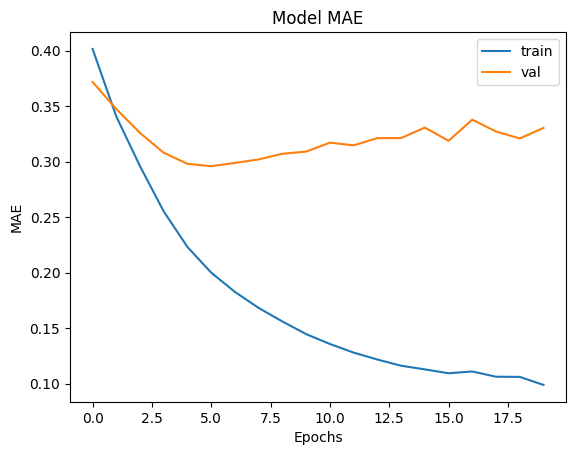

In [23]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('Model MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend(['train', 'val'])
plt.show()


In [ ]:
# (14) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답14_1 = 'xlabel'
정답14_2 = 'ylabel'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. y축 이름을 지정하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 6글자이고 첫 글자는 `y` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('Model MAE')
plt.xla___('Epochs')
plt.yla___('MAE')
plt.legend(['train', 'val'])
plt.show()

정답14_1 = 'xla___'   # 빈칸 1에 넣은 단어
정답14_2 = 'yla___'   # 빈칸 2에 넣은 단어
```

</details>